# 08 - Prediction, forecast and warming scenarios
**Heat, Rain & Harvest.** Phase 8. Train 1997-2017, test 2018-2022 (time-based split; nothing from the test years is used
for fitting, scaling, trends or tuning). All numbers here are read from `data/processed/phase8/`, produced by
`python -m src.run_phase8` (see DECISIONS D18, D19).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import PROCESSED, FIGURES
from src.boundaries import load_pc11_districts
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
save = lambda fig, n: fig.savefig(FIGURES / f"{n}.png", bbox_inches="tight", dpi=150)
OUT = PROCESSED / "phase8"; geo = load_pc11_districts()
summary = json.load(open(OUT / "run_summary.json"))
for k, v in summary.items(): print(k, "features:", v["features"], "| log rain:", v["log_rain"])

Wheat features: ['tmax_mean', 'tmin_mean', 'gdd', 'edd', 'mar_tmax_mean', 'mar_hot_days_35', 'edd_mar', 'rain_total', 'rain_nov_jan', 'rainy_days', 'rain_cv_monthly', 'feb_tmax_mean', 'edd30_feb_mar', 'prev_monsoon_rain'] | log rain: True
Rice (monsoon) features: ['tmax_mean', 'tmin_mean', 'gdd', 'edd', 'hot_days_35', 'rain_total', 'rain_jun_sep', 'rainy_days', 'rain_cv_monthly', 'longest_dry_spell'] | log rain: False


## 1. Do the models beat the trend-only baseline? (test years 2018-2022)
**Skill vs baseline** = 1 - MSE(model) / MSE(baseline). Positive = better than just extending each district's trend.


Wheat - TEST
                             RMSE t/ha  MAE t/ha  skill vs baseline  corr(anomaly)
model                                                                             
Baseline (trend only)           0.5064    0.3925             0.0000            NaN
FE regression (OLS, within)     0.5163    0.3984            -0.0396         0.1182
Ridge                           0.5018    0.3849             0.0181         0.0522
Random forest                   0.5045    0.3892             0.0073         0.0233
Gradient boosting               0.5162    0.3991            -0.0390         0.0382
Wheat - TRAIN skill (in-sample): {'Baseline (trend only)': 0.0, 'FE regression (OLS, within)': 0.133, 'Ridge': 0.104, 'Random forest': 0.258, 'Gradient boosting': 0.228}

Rice (monsoon season) - TEST
                             RMSE t/ha  MAE t/ha  skill vs baseline  corr(anomaly)
model                                                                             
Baseline (trend only)           0.5494 

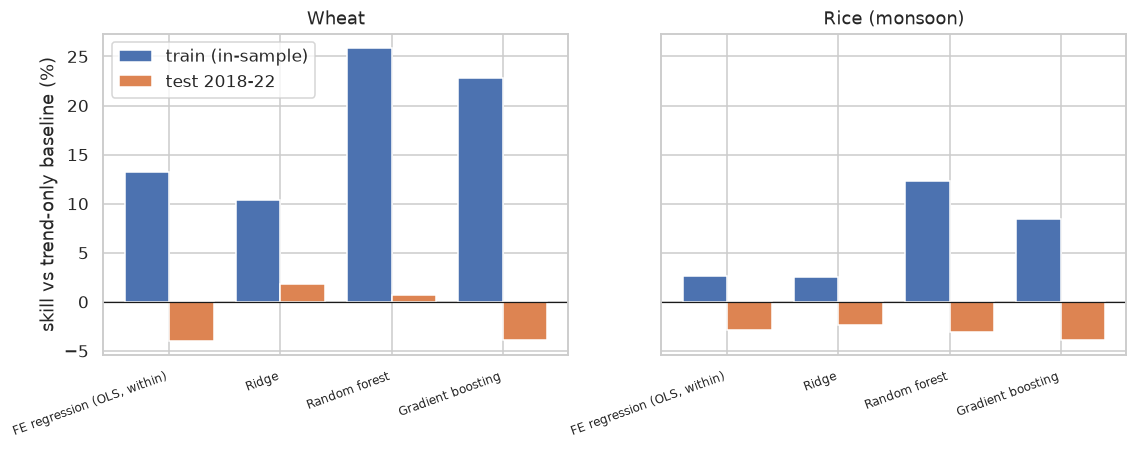

In [2]:
for key, name in (("wheat", "Wheat"), ("rice_monsoon", "Rice (monsoon season)")):
    te = pd.read_csv(OUT / f"eval_test_{key}.csv", index_col=0); trn = pd.read_csv(OUT / f"eval_train_{key}.csv", index_col=0)
    print(f"\n{name} - TEST"); print(te.round(4).to_string())
    print(f"{name} - TRAIN skill (in-sample):", trn["skill vs baseline"].round(3).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, key, name in ((ax[0], "wheat", "Wheat"), (ax[1], "rice_monsoon", "Rice (monsoon)")):
    te = pd.read_csv(OUT / f"eval_test_{key}.csv", index_col=0)["skill vs baseline"].drop("Baseline (trend only)")
    trn = pd.read_csv(OUT / f"eval_train_{key}.csv", index_col=0)["skill vs baseline"].drop("Baseline (trend only)")
    x = np.arange(len(te)); a.bar(x - .2, trn.values * 100, .4, label="train (in-sample)"); a.bar(x + .2, te.values * 100, .4, label="test 2018-22")
    a.axhline(0, c="k", lw=.8); a.set_xticks(x); a.set_xticklabels(te.index, rotation=20, ha="right", fontsize=8); a.set_title(name)
ax[0].set_ylabel("skill vs trend-only baseline (%)"); ax[0].legend()
save(fig, "08_skill_train_vs_test"); plt.show()

**Reading this honestly:** flexible models (random forest, boosting) look good in-sample and lose that advantage on
new years, which is overfitting. On test years every model is within a few percent of the baseline. Weather explains
only a small share of year-to-year yield variation out of sample (about 1-2% in training-year cross-validation, D19).

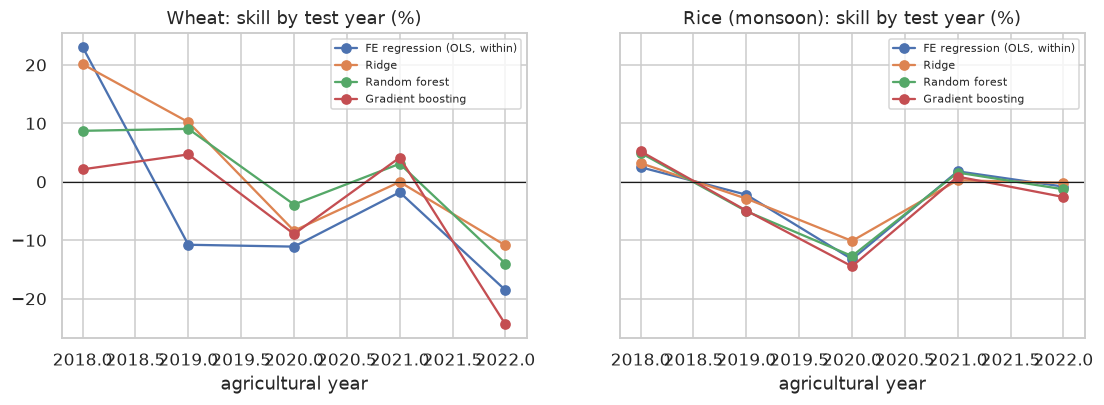

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for a, key, name in ((ax[0], "wheat", "Wheat"), (ax[1], "rice_monsoon", "Rice (monsoon)")):
    s = pd.read_csv(OUT / f"skill_by_year_{key}.csv", index_col=0).drop(columns="Baseline (trend only)") * 100
    s.plot(ax=a, marker="o"); a.axhline(0, c="k", lw=.8); a.set(title=f"{name}: skill by test year (%)", xlabel="agricultural year")
    a.legend(fontsize=7)
save(fig, "08_skill_by_year"); plt.show()

## 2. The pre-harvest wheat forecast
The wheat weather window ends on **31 March** and the preceding-monsoon rain is known before sowing, so every wheat
prediction above is a **pre-harvest forecast** (harvest is in April). How did it do in the 2021-22 heatwave season?

2021-22 Punjab+Haryana: actual vs trend -12.3%, Ridge forecast vs trend +3.7%  (median over districts, n=41)
2021-22 All India (sample): actual vs trend +4.6%, Ridge forecast vs trend +2.6%  (median over districts, n=368)


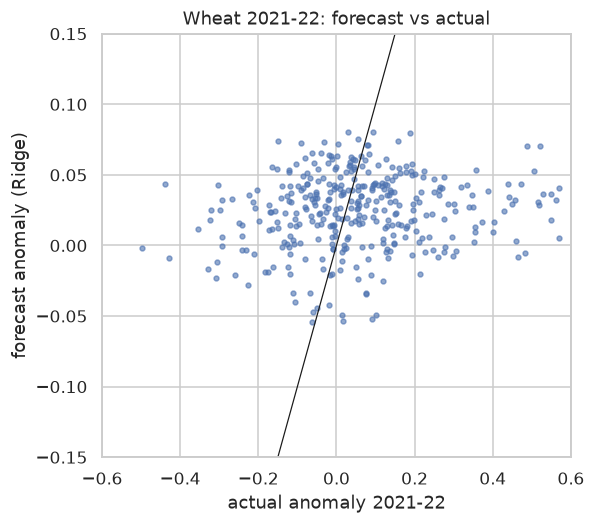

In [4]:
p = pd.read_parquet(OUT / "predictions_wheat.parquet")
p = p[~p.train & p.yield_t_ha.notna()].copy()
best = "pred_Ridge"
for yr in (2021,):
    g = p[p.year == yr]
    for region, ids in (("Punjab+Haryana", [3, 6]), ("All India (sample)", None)):
        s = g if ids is None else g[g.state_id.isin(ids)]
        print(f"{yr}-{yr-1999:02d} {region}: actual vs trend {(s.yield_t_ha/s.trend_train-1).median()*100:+.1f}%, "
              f"Ridge forecast vs trend {(s[best]/s.trend_train-1).median()*100:+.1f}%  (median over districts, n={len(s)})")
fig, ax = plt.subplots(figsize=(5.5, 5))
g = p[p.year == 2021]
ax.scatter(g.yield_t_ha / g.trend_train - 1, g[best] / g.trend_train - 1, s=10, alpha=.6)
ax.axline((0, 0), slope=1, c="k", lw=.8); ax.set(xlabel="actual anomaly 2021-22", ylabel="forecast anomaly (Ridge)",
       title="Wheat 2021-22: forecast vs actual"); ax.set_xlim(-.6, .6); ax.set_ylim(-.15, .15)
save(fig, "08_forecast_2022"); plt.show()

The forecast anomalies are tiny compared with what happened (note the different axis ranges): the model is very
cautious (Ridge shrinks coefficients) and it did not anticipate the Punjab-Haryana losses. As an early-warning tool for
heat damage it is **not** good enough; this is reported as a limitation.

## 3. Yield-loss classifier (loss = more than 10% below the train-only trend)

In [5]:
for key, name in (("wheat", "Wheat"), ("rice_monsoon", "Rice (monsoon)")):
    print(f"\n{name}"); print(pd.read_csv(OUT / f"eval_classifier_{key}.csv", index_col=0).round(3).to_string())


Wheat
                                    ROC-AUC  PR-AUC  Brier  balanced acc (thr 0.5)  loss share in test
model                                                                                                 
Baseline (district loss frequency)    0.584   0.204  0.138                   0.545                0.15
Logistic (balanced)                   0.562   0.163  0.246                   0.542                0.15
Gradient boosting                     0.578   0.172  0.237                   0.546                0.15

Rice (monsoon)
                                    ROC-AUC  PR-AUC  Brier  balanced acc (thr 0.5)  loss share in test
model                                                                                                 
Baseline (district loss frequency)    0.576   0.276  0.188                   0.554                0.24
Logistic (balanced)                   0.494   0.261  0.261                   0.491                0.24
Gradient boosting                     0.530   0.26

ROC-AUC 0.5 = coin flip, 1 = perfect. The baseline (each district's historical loss frequency) is hard to beat:
knowing *where* losses usually happen is about as informative as this year's weather.

## 4. Robustness of the main heat effect (district + year fixed effects, clustered SE)


Wheat: effect of +1 C season night temperature on relative yield
                                variant    n  effect per +1C night temp  ci_low  ci_high   p
        main (area >= 1000 ha, 3x flag) 9793                      -5.27   -6.59    -3.95 0.0
        drop Madhya Pradesh 2018+ (D15) 9550                      -5.70   -7.10    -4.31 0.0
drop districts with split parents (D6c) 9740                      -5.31   -6.64    -3.98 0.0
                 stricter flag 2x (D11) 9538                      -4.56   -5.85    -3.26 0.0
                   looser flag 4x (D11) 9793                      -5.27   -6.59    -3.95 0.0
                  area >= 5000 ha (D14) 8629                      -5.45   -6.84    -4.06 0.0
             train years only (<= 2017) 7904                      -5.80   -7.29    -4.31 0.0
                    area-weighted (WLS) 9793                      -4.52   -5.84    -3.20 0.0

Rice (monsoon): effect of +1 C season night temperature on relative yield
                      

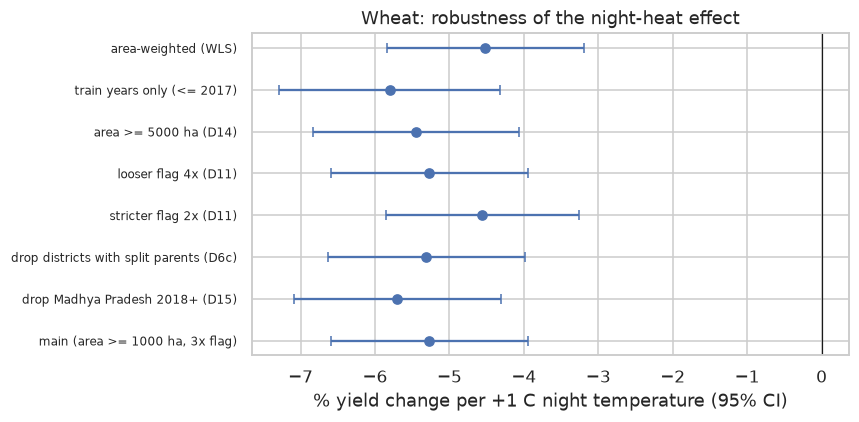

In [6]:
for key, name in (("wheat", "Wheat"), ("rice_monsoon", "Rice (monsoon)")):
    r = pd.read_csv(OUT / f"robustness_{key}.csv")
    print(f"\n{name}: effect of +1 C season night temperature on relative yield")
    print(r.assign(**{c: r[c] * 100 for c in ["effect per +1C night temp", "ci_low", "ci_high"]}).round(2).to_string(index=False))
r = pd.read_csv(OUT / "robustness_wheat.csv")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(r["effect per +1C night temp"] * 100, range(len(r)), xerr=[(r["effect per +1C night temp"] - r.ci_low) * 100,
            (r.ci_high - r["effect per +1C night temp"]) * 100], fmt="o", capsize=3)
ax.set_yticks(range(len(r))); ax.set_yticklabels(r.variant, fontsize=8); ax.axvline(0, c="k", lw=.8)
ax.set(xlabel="% yield change per +1 C night temperature (95% CI)", title="Wheat: robustness of the night-heat effect")
save(fig, "08_robustness_wheat"); plt.show()

## 5. Warming scenarios: +1 C and +2 C
Every daily max and min temperature is raised by 1 or 2 C, the season features are recomputed from the daily data, and
the fixed-effects model predicts the change in yield for the 2018-22 seasons. **Assumptions:** uniform warming, unchanged
rain, no adaptation (same sowing dates, varieties, irrigation). Warming of 2 C lies partly outside the variation seen in
1997-2017, so these are model extrapolations, not forecasts.


Wheat: area-weighted mean change in yield (% of trend)
  +1 C: -5.7%   (districts: 10th pct -12.8%, median -5.4%, 90th pct -4.3%)
     by irrigation: {'<50%': -14.3, '50-90%': -8.3, '>90%': -4.7}
  +2 C: -11.3%   (districts: 10th pct -26.0%, median -10.6%, 90th pct -8.4%)
     by irrigation: {'<50%': -29.1, '50-90%': -16.6, '>90%': -9.2}
     +2 C by risk zone: {'Zone 1 (loss years 15%): mild March, high irrigation': -9.2, 'Zone 2 (loss years 19%): hot March, high irrigation': -10.5, 'Zone 3 (loss years 30%): hot March, mixed irrigation': -16.4, 'Zone 4 (loss years 31%): mild March, low irrigation': -26.7, 'Zone 5 (loss years 34%): hot March, high irrigation': -13.2}


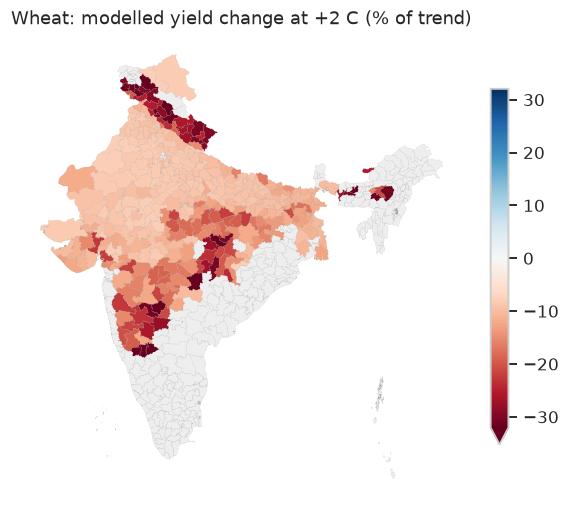


Rice (monsoon): area-weighted mean change in yield (% of trend)
  +1 C: -4.4%   (districts: 10th pct -7.7%, median -4.2%, 90th pct -1.7%)
     by irrigation: {'<50%': -6.1, '50-90%': -4.1, '>90%': -2.2}
  +2 C: -7.5%   (districts: 10th pct -14.3%, median -7.3%, 90th pct -2.0%)
     by irrigation: {'<50%': -10.6, '50-90%': -7.1, '>90%': -3.4}


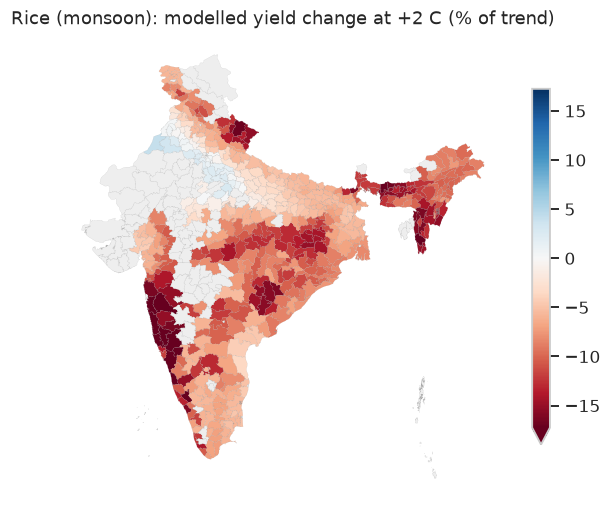

In [7]:
prof = pd.read_parquet(PROCESSED / "district_profiles.parquet")
zones = pd.read_csv(PROCESSED / "risk_zones_wheat.csv", index_col=0)
for key, name in (("wheat", "Wheat"), ("rice_monsoon", "Rice (monsoon)")):
    s = pd.read_parquet(OUT / f"scenarios_{key}.parquet")
    d = s.groupby(["unit_id", "delta_c"]).agg(delta=("delta_rel_yield", "mean"), area=("area_ha", "mean"), irr=("irr_static", "first")).reset_index()
    print(f"\n{name}: area-weighted mean change in yield (% of trend)")
    for dc, g in d.groupby("delta_c"):
        print(f"  +{dc:.0f} C: {np.average(g.delta, weights=g.area)*100:+.1f}%   (districts: 10th pct {g.delta.quantile(.1)*100:+.1f}%, "
              f"median {g.delta.median()*100:+.1f}%, 90th pct {g.delta.quantile(.9)*100:+.1f}%)")
        g2 = g.assign(irr_group=pd.cut(g.irr, [0, .5, .9, 1.01], labels=["<50%", "50-90%", ">90%"]))
        print("     by irrigation:", g2.groupby("irr_group", observed=True).apply(
            lambda x: round(np.average(x.delta, weights=x.area) * 100, 1), include_groups=False).to_dict())
    if key == "wheat":
        z = d[d.delta_c == 2].set_index("unit_id").join(zones)
        print("     +2 C by risk zone:", z.groupby("zone").apply(lambda x: round(np.average(x.delta, weights=x.area) * 100, 1), include_groups=False).to_dict())
    two = d[d.delta_c == 2].set_index("unit_id").delta * 100
    g = geo.merge(two.rename("v").reset_index().rename(columns={"unit_id": "district_id"}), on="district_id", how="left")
    fig, ax = plt.subplots(figsize=(6.5, 7))
    lim = np.nanpercentile(np.abs(g.v), 98)
    g.plot(column="v", cmap="RdBu", vmin=-lim, vmax=lim, legend=True, ax=ax, linewidth=.05, edgecolor="grey",
           missing_kwds=dict(color="#eeeeee"), legend_kwds=dict(shrink=.6))
    ax.set_axis_off(); ax.set_title(f"{name}: modelled yield change at +2 C (% of trend)")
    save(fig, f"08_map_scenario_2C_{key}"); plt.show()

### 5b. Uncertainty: cluster bootstrap (300 resamples of districts, `src/scenario_uncertainty.py`)

In [8]:
R = pd.read_parquet(OUT / "scenario_bootstrap.parquet")
est = R[R.b == 0].set_index(["crop", "delta_c"])[["all", "<50%", "50-90%", ">90%"]] * 100
lo = R[R.b > 0].groupby(["crop", "delta_c"])[["all", "<50%", "50-90%", ">90%"]].quantile(.025) * 100
hi = R[R.b > 0].groupby(["crop", "delta_c"])[["all", "<50%", "50-90%", ">90%"]].quantile(.975) * 100
tab = est.round(1).astype(str) + " [" + lo.round(1).astype(str) + ", " + hi.round(1).astype(str) + "]"
print("Area-weighted yield change, % of trend, with 95% bootstrap interval (columns = irrigation group)"); print(tab.to_string())

Area-weighted yield change, % of trend, with 95% bootstrap interval (columns = irrigation group)
                                        all                  <50%                50-90%                >90%
crop           delta_c                                                                                     
Rice (monsoon) 1.0        -4.4 [-5.7, -2.6]     -6.2 [-8.5, -3.3]     -4.1 [-5.4, -2.3]   -2.2 [-4.0, -0.6]
               2.0       -7.5 [-10.4, -3.7]   -10.7 [-15.5, -4.8]     -7.1 [-9.9, -3.5]   -3.4 [-7.2, -0.4]
Wheat          1.0        -5.7 [-6.6, -4.8]  -14.3 [-17.9, -11.3]     -8.3 [-9.6, -7.0]   -4.7 [-5.6, -3.9]
               2.0      -11.3 [-13.2, -9.4]  -29.2 [-36.7, -22.9]  -16.6 [-19.3, -14.1]  -9.2 [-11.1, -7.3]


**Caution on the irrigation gradient.** Irrigation here is each district's fixed training-period share, and the
least-irrigated wheat districts are mostly cool Himalayan hill districts (risk zone 4). The gradient therefore mixes
"less irrigation" with "different climate and location", and +2 C in the hills is an extrapolation. It is consistent with
irrigation reducing heat losses, but it is not a clean causal estimate of irrigation's protective effect (compare Phase 6:
the wheat heat x irrigation interaction was not significant on its own, p = 0.10).

## 6. Summary (written after reviewing the outputs: see LEARNING.md / VIVA.md Phase 8)